**Icha Meisya Kurnia (25031554047)**

**Putri Najwa Zuleyka Al Hasni (25031554076)**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import pandas as pd
import requests
from sklearn.feature_extraction.text import TfidfVectorizer

url = "https://api.spaceflightnewsapi.net/v4/articles/?limit=100"
response = requests.get(url)
data = response.json()

articles = [item['summary'] for item in data['results']]
df = pd.DataFrame({'prepro': articles})

df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']

vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [ ]:
k = range(1, 7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10) # jumlah cluster akan di-looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[96.51113087830693, 94.79378054225157, 90.06669916471623, 84.1547990972168, 82.88228273856426, 81.4344683496512]


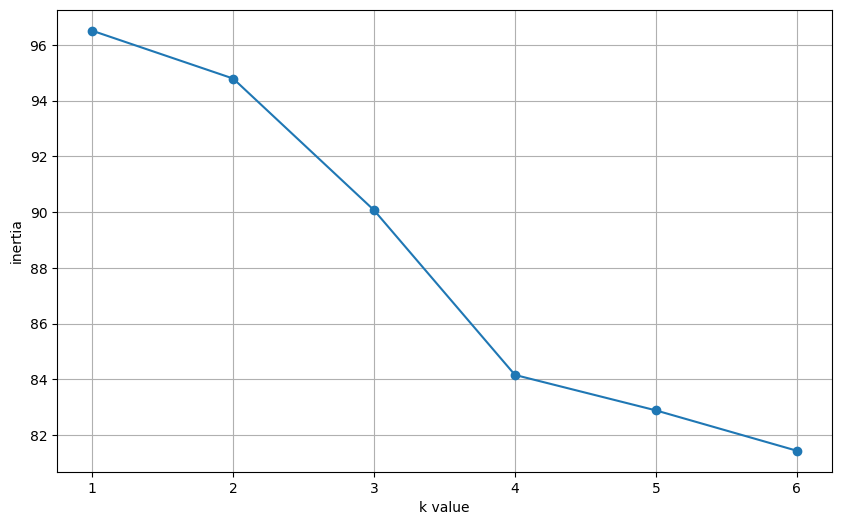

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

In [ ]:
n_clusters = 4

In [ ]:
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

KMeans(n_clusters=4, random_state=10)

In [ ]:
df['Kmeans_label'] = kM.labels_
df.head()

,prepro,Kmeans_label
0,"\nSAN FRANCISCO —October 26, 2026—Today, Astra...",1
1,Falcon 9’s retirement could leave the market u...,0
2,The Australian government has submitted a coun...,1
3,With its solar arrays integrated and key quali...,0
4,APOD Science APOD 2026 October 26 – M42: The… ...,3


In [ ]:
from sklearn import metrics
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.09684725100756919)

Kmeans for cluster 0


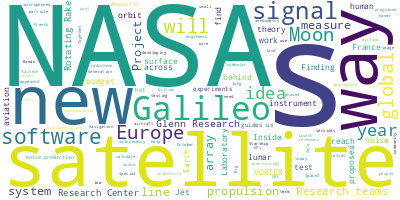

In [ ]:
c = 0
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


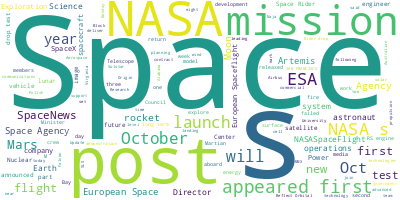

In [ ]:
c = 1
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


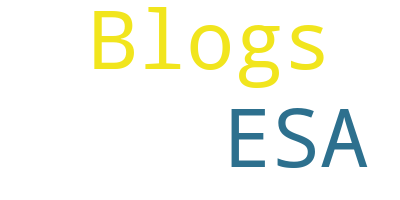

In [ ]:
c = 2
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


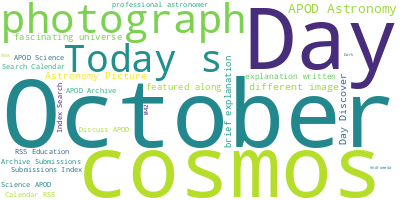

In [ ]:
c = 3
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ' '.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

In [ ]:
X = X
y = df['Kmeans_label']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[ 2  4  0]
 [ 0 23  0]
 [ 0  0  1]]
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         6
           1       0.85      1.00      0.92        23
           2       1.00      1.00      1.00         1

    accuracy                           0.87        30
   macro avg       0.95      0.78      0.81        30
weighted avg       0.89      0.87      0.84        30



In [ ]:
testing = "SpaceX launched a Falcon 9 rocket carrying new Starlink satellites into Earth orbit."
testing_vec = vectorizer.transform([testing])
testing_pred = model.predict(testing_vec)
print(testing_pred)

[0]


Grafik Elbow tidak menunjukkan penurunan yang tajam, menandakan topik berita antariksa cukup seragam. Nilai Silhouette Score yang mendekati nol mengindikasikan bahwa batas antar-cluster saling tumpang tindih akibat banyaknya kata kunci teknis yang sering muncul secara bersamaan. Pengelompokan ini memisahkan isi berita ke dalam beberapa variasi, mulai dari topik umum tentang roket dan stasiun luar angkasa hingga topik yang lebih spesifik seperti entitas SpaceX, NASA, dan satelit. Pengujian dengan Random Forest Classifier mengonfirmasi bahwa pola kata kunci dari tiap cluster tersebut dapat dipelajari kembali dengan baik oleh model.